# Practical Exercise — Introduction to Deep Generative Models
**Arthur SATOUF**  
# TP 1.2 — Variational Autoencoders on Fashion MNIST

For each practical exercise (TP), please work in groups of two or three. Then, create a **private GitHub repository** and add me (my GitHub is **arthur-75**) to your project.

> Complete the `xxx` placeholders and the requested sections. No solutions are provided. Some cells cannot run until you have completed the exercise.

Use pytorch documentation https://docs.pytorch.org/docs/2.14/index.html to solve.


## 1. Data Preparation and Visualization
*Identical to the first practical exercise.*

**Goal:**
- Load the Fashion MNIST dataset and pad images to 32 × 32.
- Create DataLoaders for training and validation.
- Visualize a few samples to confirm data integrity.

**Key points to recall:**
- Why do we pad the images from 28 × 28 to 32 × 32?
- Which transformations can help (e.g., normalization)?
- How do we shuffle and batch the data for efficient training?

Refer back to Step 1 of the first exercise for detailed guidance.

In [2]:
# Reuse your data preparation from TP 1.1 here.
# TODO: Import required libraries; prepare Fashion MNIST and DataLoaders;
#       select a device; visualize some examples.

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

In [3]:
# Preprocessing
transform = transforms.Compose([
    transforms.Resize(32),  # Pad 28x28 images to 32x32
    transforms.ToTensor()  # Convert images to tensors
])
batch_size = 16

In [4]:
# Load data
train_dataset = datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=False)
val_dataset = datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)
val_loader = DataLoader(dataset=val_dataset,batch_size=batch_size , shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.13MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.8MB/s]


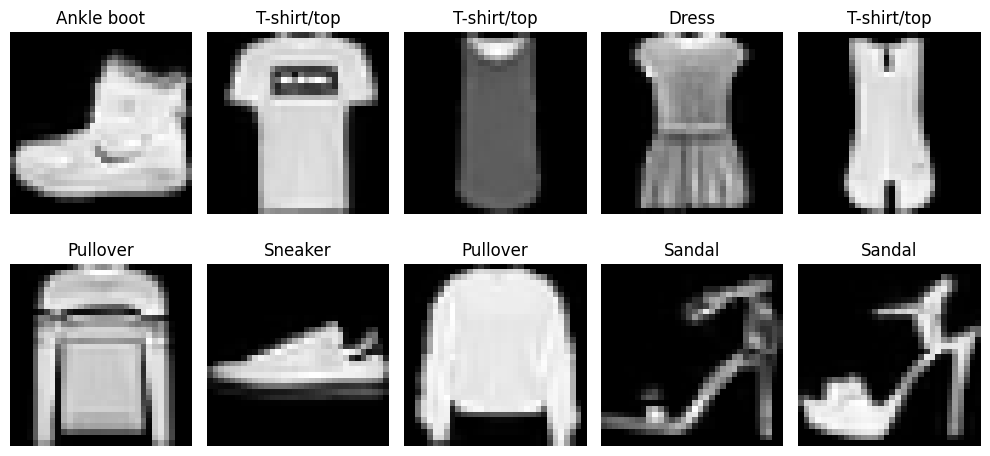

In [5]:
class_labels = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

def plot_sample_images(loader):
    data_iter = iter(loader)
    images, labels = next(data_iter)
    images = images.numpy()

    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(class_labels[labels[i].item()])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(train_loader)

## 2. Define the VAE Model

**Key difference from a standard autoencoder:** Instead of directly learning a latent vector $z$, the VAE learns a distribution $\mathcal{N}(\mu,\sigma^2)$ by predicting $\mu$ (mean) and $\log(\sigma^2)$ (log-variance), using a **reparameterization trick**.

**Guided outline:**
1. **Encoder:** Convolutional layers reduce spatial dimensions and extract features. Use two separate heads: one for $\mu$ and one for $\log(\sigma^2)$.
2. **Reparameterization:** Implement a function like `reparameterize(mu, logvar)`.
3. **Decoder:** Transposed convolution layers reconstruct the image from $z$; use Sigmoid at output so pixel values remain between 0 and 1.

**Questions (answer yourself):**
- Why do we need separate heads for $\mu$ and $\log(\sigma^2)$?
- How does the reparameterization trick help with backpropagation through stochastic nodes?

**Answers :**
Car on doit pas utiliser des informations de la validation dans le train.

In [19]:
class VAE(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        """
        Variational Autoencoder initialization.

        Args:
            input_shape (tuple): Shape of input image, default (1, 32, 32).
            latent_dim (int): Dimension of the latent representation.
        """
        super(VAE, self).__init__()

        # ------------------
        # 1. Encoder
        # ------------------
        # Progressively reduce the spatial dimensions with Conv2d, stride=2.
        self.encoder = nn.Sequential(
            # First convolutional layer: 1 channel -> 32 feature maps
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),  # Activation function

            # Second convolutional layer
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),  # Activation function

            # Third convolutional layer
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),  # TODO: Conv2d with 128 filters, kernel_size=3, stride=2, padding=1
            nn.Sigmoid()  # Activation function
        )

        # Dynamically calculate the flattened size after convolution layers.
        flattened_size, decode_shape = self.calculate_flattened_size(
            self.encoder, input_shape
        )

        # ------------------
        # 2. Fully Connected Layers for Latent Space
        # ------------------
        # Two separate heads: fc_mu and fc_logvar.
        self.fc_mu = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)  # Latent mean
        )
        self.fc_logvar = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)  # Hint: same dimension as mu
        )

        # ------------------
        # 3. Decoder
        # ------------------
        # Invert the encoder with ConvTranspose2d (deconvolutions).
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flattened_size),  # Latent space -> feature map
            nn.Unflatten(decode_shape[0], decode_shape[1:]),

            # Transposed convolution layers
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),  # Activation

            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),  # TODO: ConvTranspose2d, 64 -> 32 channels, k=3, stride=2, padding=1, output_padding=1
            nn.ReLU(),  # Activation

            # Final layer: single-channel grayscale output
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()  # TODO: Activation; output should be between 0 and 1
        )

    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick: z = mu + sigma * eps, eps ~ N(0, I).

        Args:
            mu (Tensor): Mean of the latent distribution.
            logvar (Tensor): Log-variance of the latent distribution.
        Returns:
            z (Tensor): Latent variable sampled from N(mu, sigma^2).
        """
        std = torch.exp(0.5 * logvar)  # Convert log-variance to std
        eps = torch.randn_like(std)    # Sample standard normal noise
        return mu + torch.exp(logvar/2) * eps

    def calculate_flattened_size(self, model, input_shape):
        # Same as in the previous exercise.
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
            return output.numel(), output.shape

    def forward(self, x):
        """
        1) Encode into mu and logvar.
        2) Sample z with the reparameterization trick.
        3) Decode z into a reconstructed image.
        Returns: recon_x, mu, logvar, z.
        """
        x_encoded = self.encoder(x)
        mu = self.fc_mu(x_encoded)
        logvar = self.fc_logvar(x_encoded)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decoder(z)
        return recon_x, mu, logvar, z

### Test — Dimension consistency
Complete the VAE before running this test. The original exercise uses `Autoencoder()` in this test; it is retained as supplied.

In [20]:
# Test dimension consistency (as supplied in the PDF)
x_sample = torch.randn(1, 1, 32, 32)
model_test = VAE()
image_test, mu, logvar, z = model_test(x_sample)
assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"

## 3. VAE Loss Function and Training

The **VAE loss** combines:
1. Reconstruction loss (e.g., Binary Cross Entropy or MSE).
2. Kullback–Leibler (KL) divergence to regularize the latent space.

**β-VAE:** Introduces a hyperparameter $eta$ to weight the KL term. With $eta=1$, this is the standard VAE. Larger $eta$ emphasizes KL regularization, often leading to more disentangled representations but potentially poorer reconstructions.

**Training flow:** For each batch, compute $\mu$, $\log(\sigma^2)$, $z$ and the reconstruction; compute `vae_loss = reconstruction_loss + β * KL_loss`; backpropagate and update parameters.

**Question:** How does a larger $eta$ value change the trade-off between reconstruction quality and latent disentanglement?

Larger $eta$ give an higher latent disentanglement but a lower reconstruction quality.

In [26]:
#######################
# 1. Define VAE Loss
#######################
def vae_loss(recon_x, x, mu, logvar, beta=1):
    """
    VAE loss: reconstruction loss (BCE or MSE) + beta * KL divergence.

    Args:
        recon_x: Reconstructed images.
        x: Original images.
        mu: Latent mean.
        logvar: Latent log-variance.
        beta: Weight for the KL divergence.
    Returns:
        total_loss: Reconstruction loss + beta * KL divergence.
    """
    # 1) Reconstruction Loss (BCE for images in [0, 1]).
    recon_loss = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # 2) KL divergence: q(z|x) should be near N(0, I).
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - torch.exp(logvar))
    return recon_loss + beta * kl_div

In [27]:
#######################
# 2. Training Function
#######################

from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, train_loader, val_loader, epochs, beta=1):
    """Train a VAE using a specified beta for KL divergence."""
    # Choose optimizer (e.g., Adam, lr=1e-4).
    optimizer =  optim.Adam(model.parameters(), lr=0.0001)
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        tqdm_loader = tqdm(train_loader, desc=f"Training Epoch {epoch + 1}/{epochs}")

        for x, _ in tqdm_loader:
            # 1) Zero previous gradients.
            optimizer.zero_grad()
            # 2) Move batch to CPU, CUDA, or MPS.
            x = x.to(device)
            # 3) Forward pass: encode -> reparameterize -> decode.
            recon_x, mu, logvar, _ = model(x)
            # 4) Compute VAE loss.
            loss = vae_loss(recon_x, x, mu, logvar, beta=beta)
            # 5) Backpropagation.
            loss.backward()
            # 6) Update parameters.
            optimizer.step()

            total_loss += loss.item()
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / len(train_loader.dataset)
        avg_val_loss, _ = evaluate_model(model, val_loader)
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Train Loss: {avg_train_loss:.4f}, "
            f"Val Loss: {avg_val_loss:.4f}"
        )
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
    plot_training_loss(train_losses, val_losses)

In [28]:
#######################
# 3. Evaluation Function
#######################
def evaluate_model(model, loader, beta=1):
    """
    Evaluate a VAE on validation or test data.
    Returns: average loss and a placeholder for another metric.
    """
    model.eval()
    total_loss = 0
    ce_loss_placeholder = 0

    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)  # Move data to model device.
            recon_x, mu, logvar, _ = model(x)
            loss = vae_loss(recon_x, x, mu, logvar, beta=beta)
            total_loss += loss.item()
            # Optionally track another metric here.

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, ce_loss_placeholder


def plot_training_loss(train_losses, val_losses):
    """Plot training and validation loss across epochs."""
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss", marker="o")
    plt.plot(val_losses, label="Validation Loss", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()

### Train
Run **at least one epoch**, then load the pretrained model, as instructed in the PDF.

Training Autoencoder...


Evaluating: 100%|██████████| 625/625 [00:02<00:00, 287.71it/s]


Epoch [1/1], Train Loss: 399.0003, Val Loss: 372.5094


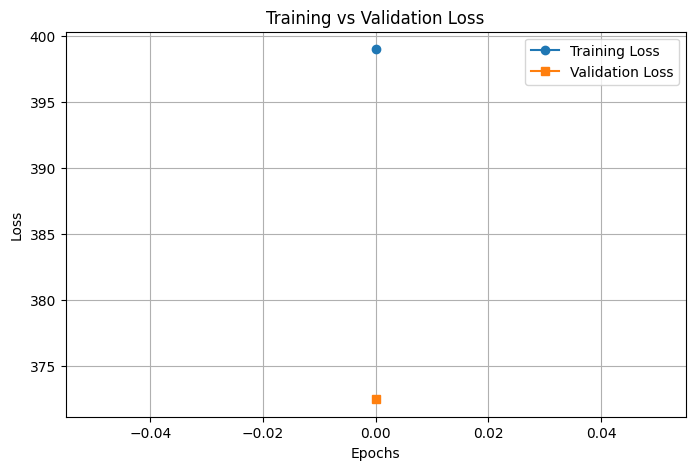

In [29]:
from tqdm import tqdm
# Train and visualize VAE.
vae = VAE().to(device)
print("Training Autoencoder...")
train_model(vae, train_loader, val_loader, epochs=1, beta=1.5)

### Load the pretrained model
Specify the path to the pretrained state dictionary. The PDF does not supply an actual file path.

In [33]:
# Load state dictionaries (starter code from PDF).
path = "vae.pt"
train_model.load_state_dict(torch.load(path, map_location=device))
train_model.eval()

AttributeError: 'function' object has no attribute 'load_state_dict'

## 4. Reconstruct Images
*Similar to Step 4 in the first practical exercise.*

**Goal:** Take a batch of original images, pass them through the VAE, and plot originals and reconstructions side by side.

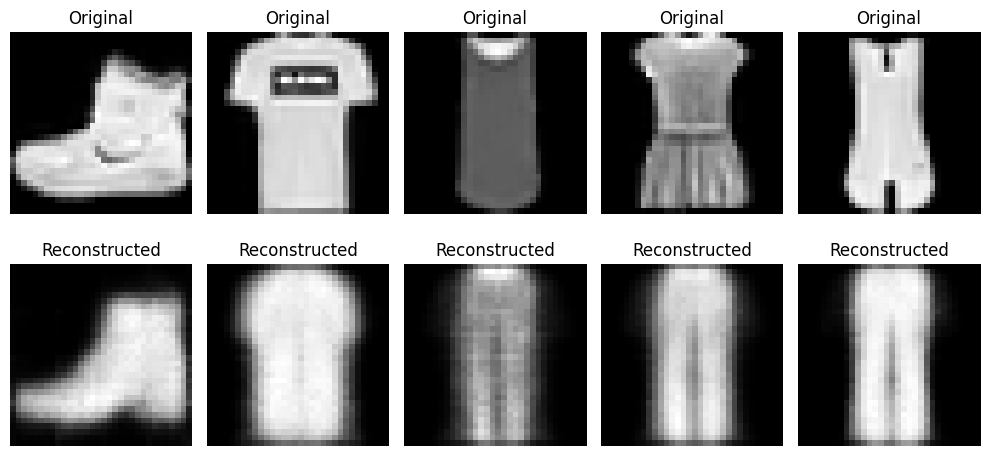

In [30]:
def plot_reconstructions(model, loader_or_z, ex=True, num_samples=5):
    """
    Plot original and reconstructed images from a VAE.
    loader_or_z: DataLoader of images or sampled latent vectors.
    ex: True for real-image examples, False for latent-vector generation.
    """
    model.eval()
    model = model.to("cpu")

    with torch.no_grad():
        if ex:
            for x, _ in loader_or_z:
                recon_x, _, _, _ = model(x)
                break
        else:
            x = None
            recon_x = model.decoder(loader_or_z)

    if x is not None:
        x = x.cpu().numpy()
    recon_x = recon_x.cpu().numpy()

    plt.figure(figsize=(10, 5))
    for i in range(num_samples):
        if x is not None:
            plt.subplot(2, num_samples, i + 1)
            plt.imshow(x[i].squeeze(), cmap="gray")
            plt.title("Original")
            plt.axis("off")

        plt.subplot(2, num_samples, i + 1 + num_samples)
        plt.imshow(recon_x[i].squeeze(), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_reconstructions(vae, train_loader, ex=True)

## 5. Visualize the Latent Space
*Similar to Step 5 in the first practical exercise.*

**Goal:** Extract 2D latent embeddings by forwarding images through the encoder. Plot them in a 2D scatter plot, colored by Fashion MNIST class.

In [35]:
embeddings = []
labels = []

vae = vae.to(device)
with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        _,_,_,latent = vae.forward(x)

        # Convert to NumPy and store results.
        embeddings.append(latent.cpu().numpy())
        labels.append(y.numpy())

embeddings = np.concatenate(embeddings, axis=0)
labels = np.concatenate(labels, axis=0)
unique_labels = np.unique(labels)
vae = vae.to("cpu")

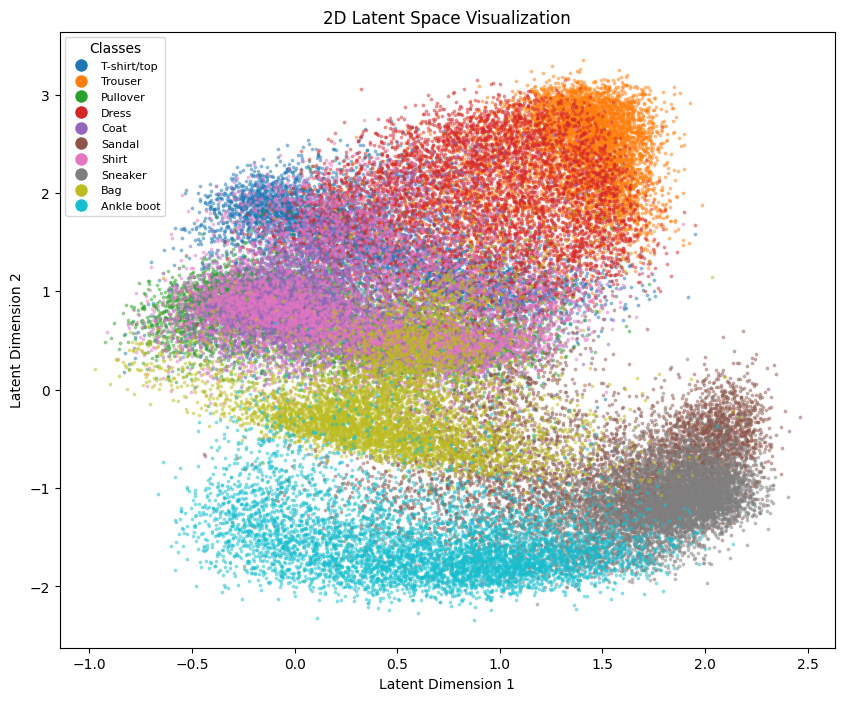

In [36]:
# Plot the 2D embeddings.
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

plt.figure(figsize=(10, 8))
legend_handles = []
for i, label in enumerate(unique_labels):
    indices = np.where(labels == label)[0]
    scatter = plt.scatter(
        embeddings[indices, 0], embeddings[indices, 1],
        c=[colors[i]], alpha=0.4, s=3, label=class_labels[label]
    )
    legend_handles.append(
        Line2D([0], [0], marker='o', color='w', label=f'{class_labels[label]}',
               markersize=10, markerfacecolor=colors[i])
    )

plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.title('2D Latent Space Visualization')
plt.legend(handles=legend_handles, title='Classes', loc='upper left', fontsize=8)
plt.show()

## 6. Generate New Images
*Similar to Step 6 in the first practical exercise.*

**Goal:** Sample random points $z$ from a Gaussian distribution (e.g., $\mathcal{N}(0,I)$) or from learned ranges of $\mu$ and $\log(\sigma^2)$; pass these points through the decoder; observe the generated images.

tensor([[-0.9561, -1.3398],
        [ 1.5452,  0.9450],
        [ 0.1280, -0.5473],
        [ 2.2711, -0.0861],
        [ 0.2524,  0.1595]])


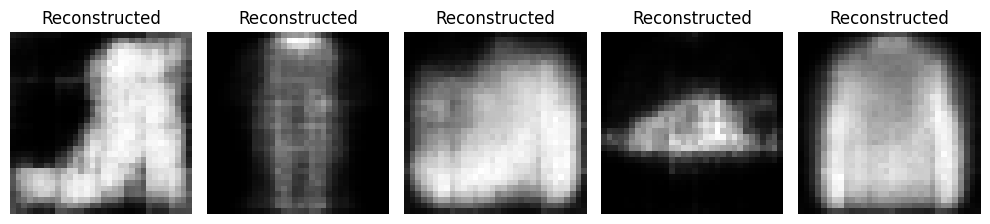

In [38]:
z_sample = torch.tensor(np.random.normal(size=(5, 2)), dtype=torch.float32)
print(z_sample)
plot_reconstructions(vae, z_sample, ex=False)

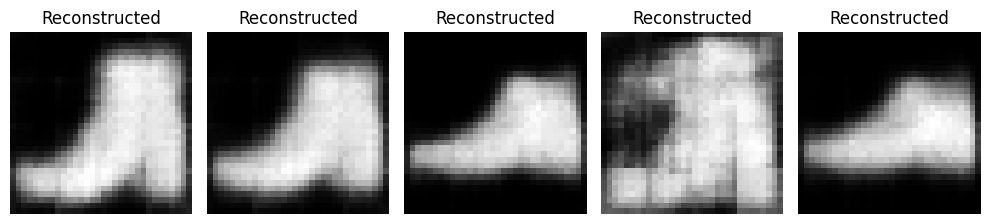

In [39]:
x_sample = torch.tensor([[0., -1.5], [0.5, -1.5], [1.5, -2], [-1., -0.5], [1.5, -1.5]])
plot_reconstructions(vae, x_sample, ex=False)